<div style="background-color:#1f3a5f; padding:24px; border-radius:10px; text-align:center;">
  <h1 style="color:white; margin:0;">Twitter Sentiment Analysis</h1>
  <h3 style="color:#a8c4e0; margin:8px 0 0 0;">1. Exploratory Data Analysis</h3>
</div>

<div style="background-color:#e8e4dc; padding:10px; border-radius:6px; text-align:center;">
  <h2 style="color:#1f3a5f; margin:0;">1. Load the Data</h2>
</div>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [14]:
cols = ["id","entity","sentiment","text"]
training = pd.read_csv("../data/raw/twitter_training.csv",header = None,names = cols)
validation = pd.read_csv("../data/raw/twitter_validation.csv",header = None,names = cols)

<div style="background-color:#e8e4dc; padding:10px; border-radius:6px; text-align:center;">
  <h2 style="color:#1f3a5f; margin:0;">2. Review Data structure</h2>
</div>

In [18]:
pd.set_option("max_colwidth",None)

In [19]:
training.head()

,id,entity,sentiment,text
0,2401,Borderlands,Positive,"im getting on borderlands and i will murder you all ,"
1,2401,Borderlands,Positive,"I am coming to the borders and I will kill you all,"
2,2401,Borderlands,Positive,"im getting on borderlands and i will kill you all,"
3,2401,Borderlands,Positive,"im coming on borderlands and i will murder you all,"
4,2401,Borderlands,Positive,"im getting on borderlands 2 and i will murder you me all,"


In [20]:
validation.head()

,id,entity,sentiment,text
0,3364,Facebook,Irrelevant,"I mentioned on Facebook that I was struggling for motivation to go for a run the other day, which has been translated by Tom’s great auntie as ‘Hayley can’t get out of bed’ and told to his grandma, who now thinks I’m a lazy, terrible person 🤣"
1,352,Amazon,Neutral,BBC News - Amazon boss Jeff Bezos rejects claims company acted like a 'drug dealer' bbc.co.uk/news/av/busine…
2,8312,Microsoft,Negative,@Microsoft Why do I pay for WORD when it functions so poorly on my @SamsungUS Chromebook? 🙄
3,4371,CS-GO,Negative,"CSGO matchmaking is so full of closet hacking, it's a truly awful game."
4,4433,Google,Neutral,Now the President is slapping Americans in the face that he really did commit an unlawful act after his acquittal! From Discover on Google vanityfair.com/news/2020/02/t…


In [21]:
training.shape

(74682, 4)

In [25]:
training.isna().sum()

id             0
entity         0
sentiment      0
text         686
dtype: int64

In [22]:
training.info()

<class 'pandas.DataFrame'>
RangeIndex: 74682 entries, 0 to 74681
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   id         74682 non-null  int64
 1   entity     74682 non-null  str  
 2   sentiment  74682 non-null  str  
 3   text       73996 non-null  str  
dtypes: int64(1), str(3)
memory usage: 2.3 MB


In [23]:
validation.shape

(1000, 4)

In [24]:
validation.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   id         1000 non-null   int64
 1   entity     1000 non-null   str  
 2   sentiment  1000 non-null   str  
 3   text       1000 non-null   str  
dtypes: int64(1), str(3)
memory usage: 31.4 KB


### Data Structure: Key Findings

- **Training set:** 74,682 rows × 4 columns (`id`, `entity`, `sentiment`, `text`).
- **Validation set:** 1,000 rows × 4 columns, much smaller than training.
- **Missing values:** 686 training tweets (0.9%) have no text. These rows can't be classified and will be removed. The validation set has no missing values.
- **Repeated tweets:** each `id` appears several times with slightly reworded text (e.g. `id` 2401: *"im getting on borderlands and i will murder you all"*, *"I am coming to the borders and I will kill you all"*). One original tweet was turned into several variations, so the true number of unique tweets is much smaller than 74,682.
- **Labels:** the data contains 4 sentiment labels (Positive, Negative, Neutral, **Irrelevant**), not the 3 described in the dataset documentation.
- **Data types:** `id` is an integer; `entity`, `sentiment` and `text` are strings, as expected.

<div style="background-color:#e8e4dc; padding:10px; border-radius:6px; text-align:center;">
<h2 style="color:#1f3a5f; margin:0;">3. Explanatory data analysis</h2>
</div>

In [30]:
count = training["sentiment"].value_counts()
percentage = training["sentiment"].value_counts(normalize= True)*100

In [42]:
counts = validation["sentiment"].value_counts()
percentages = validation["sentiment"].value_counts(normalize= True)*100

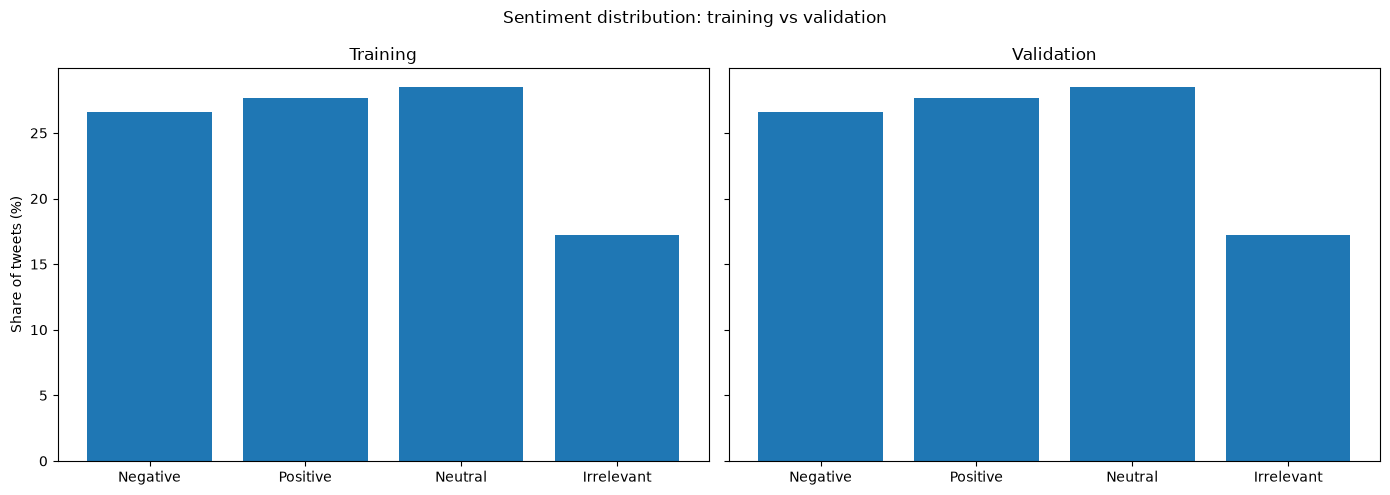

In [44]:
order = ["Negative", "Positive", "Neutral", "Irrelevant"]

fig, ax = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

ax[0].bar(order, percentage.reindex(order))
ax[0].set_title("Training")
ax[0].set_ylabel("Share of tweets (%)")

ax[1].bar(order, percentages.reindex(order))
ax[1].set_title("Validation")

fig.suptitle("Sentiment distribution: training vs validation")
plt.tight_layout()
plt.show()

In [47]:
from sklearn.feature_extraction.text import CountVectorizer

In [50]:
training = training.dropna(subset=["text"])

In [51]:
def top_words(texts, n=15):
    cv = CountVectorizer(stop_words="english")
    dtm = cv.fit_transform(texts)
    counts = pd.Series(np.asarray(dtm.sum(axis=0)).ravel(), index=cv.get_feature_names_out())
    return counts.sort_values(ascending=False).head(n)

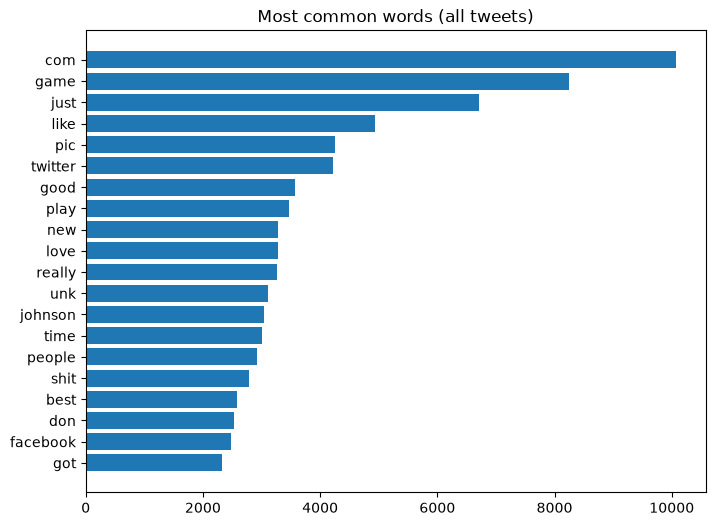

In [52]:
overall = top_words(training["text"], n=20)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(overall.index, overall.values)
ax.invert_yaxis()
ax.set_title("Most common words (all tweets)")
plt.show()